# Exercício 3 — Padronização e Escalonamento
**Dataset:** Adult Census Income (`adult.data`, documentação em `adult.names`)

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

pd.set_option('display.max_columns', 30)

In [2]:
# NOMES DAS COLUNAS (consulte a documentação do dataset)
# tirei da parte final do adult.names, na mesma ordem em que aparecem lá + a coluna alvo (income)
colunas = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
           'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
           'hours-per-week', 'native-country', 'income']

In [3]:
# CARREGAMENTO DOS DADOS
# de propósito, sem skipinitialspace e sem na_values, para ver os problemas "crus"
df_raw = pd.read_csv('adult.data', header=None, names=colunas)
print('Dimensões:', df_raw.shape)
df_raw.head()

Dimensões: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
df_raw.info()
print()
print('df.isna().sum() ->', df_raw.isna().sum().sum(), 'ausentes no total')

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB

df.isna().sum() -> 0 ausentes no total


À primeira vista está tudo perfeito: 32.561 linhas, tipos corretos (numéricas como `int64`, textos como texto) e **nenhum valor ausente** segundo o `isna()`. É aqui que mora a pegadinha.

## Inspeção das colunas categóricas

In [5]:
# INSPEÇÃO DAS COLUNAS CATEGÓRICAS
cat_cols = df_raw.select_dtypes(exclude='number').columns.tolist()
for col in cat_cols:
    valores = df_raw[col].unique()
    print(f'{col} ({len(valores)} valores):')
    print('   ', [repr(v) for v in valores[:8]], '...' if len(valores) > 8 else '')

workclass (9 valores):
    ["' State-gov'", "' Self-emp-not-inc'", "' Private'", "' Federal-gov'", "' Local-gov'", "' ?'", "' Self-emp-inc'", "' Without-pay'"] ...
education (16 valores):
    ["' Bachelors'", "' HS-grad'", "' 11th'", "' Masters'", "' 9th'", "' Some-college'", "' Assoc-acdm'", "' Assoc-voc'"] ...
marital-status (7 valores):
    ["' Never-married'", "' Married-civ-spouse'", "' Divorced'", "' Married-spouse-absent'", "' Separated'", "' Married-AF-spouse'", "' Widowed'"] 
occupation (15 valores):
    ["' Adm-clerical'", "' Exec-managerial'", "' Handlers-cleaners'", "' Prof-specialty'", "' Other-service'", "' Sales'", "' Craft-repair'", "' Transport-moving'"] ...
relationship (6 valores):
    ["' Not-in-family'", "' Husband'", "' Wife'", "' Own-child'", "' Unmarried'", "' Other-relative'"] 
race (5 valores):
    ["' White'", "' Black'", "' Asian-Pac-Islander'", "' Amer-Indian-Eskimo'", "' Other'"] 
sex (2 valores):
    ["' Male'", "' Female'"] 
native-country (42 valores):


In [6]:
# a) espaços extras no início/fim
espacos = pd.DataFrame({
    'com espaço no início': {c: df_raw[c].str.startswith(' ').sum() for c in cat_cols},
    'com espaço no fim': {c: df_raw[c].str.endswith(' ').sum() for c in cat_cols},
    'total de linhas': {c: len(df_raw) for c in cat_cols},
})
espacos

,com espaço no início,com espaço no fim,total de linhas
workclass,32561,0,32561
education,32561,0,32561
marital-status,32561,0,32561
occupation,32561,0,32561
relationship,32561,0,32561
race,32561,0,32561
sex,32561,0,32561
native-country,32561,0,32561
income,32561,0,32561


In [7]:
# b) diferenças de capitalização / grafia: se ao colocar tudo em minúsculo e sem espaço
#    o número de categorias diminuir, existem variações da mesma categoria
for col in cat_cols:
    n_original = df_raw[col].nunique()
    n_normalizado = df_raw[col].str.strip().str.lower().str.replace('_', '-').nunique()
    if n_original != n_normalizado:
        print(f'{col}: {n_original} -> {n_normalizado}')
print('(se nada apareceu acima, não há variação só de maiúscula/minúscula)')
print()
# olhando os países com calma, procurando grafias estranhas
print(sorted(df_raw['native-country'].str.strip().unique()))

(se nada apareceu acima, não há variação só de maiúscula/minúscula)

['?', 'Cambodia', 'Canada', 'China', 'Columbia', 'Cuba', 'Dominican-Republic', 'Ecuador', 'El-Salvador', 'England', 'France', 'Germany', 'Greece', 'Guatemala', 'Haiti', 'Holand-Netherlands', 'Honduras', 'Hong', 'Hungary', 'India', 'Iran', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Laos', 'Mexico', 'Nicaragua', 'Outlying-US(Guam-USVI-etc)', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Puerto-Rico', 'Scotland', 'South', 'Taiwan', 'Thailand', 'Trinadad&Tobago', 'United-States', 'Vietnam', 'Yugoslavia']


In [8]:
# c) marcadores de "valor desconhecido"
marcadores_suspeitos = ['?', 'unknown', 'Unknown', 'NA', 'N/A', 'none', 'None', '-', '']
achados = {}
for col in cat_cols:
    limpos = df_raw[col].str.strip()
    for m in marcadores_suspeitos:
        qtd = (limpos == m).sum()
        if qtd:
            achados[(col, m)] = qtd
pd.Series(achados, name='ocorrências')

workclass       ?    1836
occupation      ?    1843
native-country  ?     583
Name: ocorrências, dtype: int64

**O que eu encontrei:**

a) **Espaços extras:** *todos* os valores de texto começam com um espaço (`' State-gov'`, `' Male'`...). Isso acontece porque o arquivo separa as colunas com `", "` (vírgula + espaço) e o pandas só corta na vírgula. O efeito prático é que um filtro como `df[df['sex'] == 'Male']` retorna **zero linhas**, porque o valor real é `' Male'`.

b) **Capitalização / grafia:** não encontrei a mesma categoria escrita de jeitos diferentes (tipo "Private" e "private"). Mas tem coisa estranha nos países: `Columbia` (o país é Colombia), `Trinadad&Tobago` (Trinidad), `Holand-Netherlands`, `Hong` (Hong Kong cortado) e `South` (provavelmente South Korea, mas não dá para ter certeza). São erros de grafia vindos da origem, e o `Outlying-US(Guam-USVI-etc)` mistura vários territórios numa categoria só.

c) **Marcadores de desconhecido:** `workclass`, `occupation` e `native-country` usam `'?'` para dizer "não sei". O pandas trata isso como uma categoria normal, então ela entra em contagens, gráficos e no one-hot encoding como se fosse uma profissão chamada "?".

## Padronização dos textos (antes x depois)

In [9]:
# PADRONIZAÇÃO DOS TEXTOS (ANTES x DEPOIS)
df = df_raw.copy()

correcoes_pais = {'Columbia': 'Colombia', 'Trinadad&Tobago': 'Trinidad&Tobago',
                  'Holand-Netherlands': 'Netherlands', 'Hong': 'Hong-Kong'}

for col in cat_cols:
    df[col] = df[col].str.strip()
df['native-country'] = df['native-country'].replace(correcoes_pais)

# deixando a variável alvo mais fácil de usar (o adult.test usa '>50K.' com ponto, então já padronizo aqui)
df['income'] = df['income'].str.replace('.', '', regex=False)

antes_depois = pd.DataFrame({
    'categorias ANTES': df_raw[cat_cols].nunique(),
    'categorias DEPOIS do strip': df[cat_cols].nunique(),
})
antes_depois['exemplo antes'] = [repr(df_raw[c].iloc[0]) for c in cat_cols]
antes_depois['exemplo depois'] = [repr(df[c].iloc[0]) for c in cat_cols]
antes_depois

,categorias ANTES,categorias DEPOIS do strip,exemplo antes,exemplo depois
workclass,9,9,' State-gov','State-gov'
education,16,16,' Bachelors','Bachelors'
marital-status,7,7,' Never-married','Never-married'
occupation,15,15,' Adm-clerical','Adm-clerical'
relationship,6,6,' Not-in-family','Not-in-family'
race,5,5,' White','White'
sex,2,2,' Male','Male'
native-country,42,42,' United-States','United-States'
income,2,2,' <=50K','<=50K'


In [10]:
# teste prático do problema do espaço
print("Filtro sex == 'Male' ANTES :", (df_raw['sex'] == 'Male').sum(), 'linhas')
print("Filtro sex == 'Male' DEPOIS:", (df['sex'] == 'Male').sum(), 'linhas')

Filtro sex == 'Male' ANTES : 0 linhas
Filtro sex == 'Male' DEPOIS: 21790 linhas


O número de categorias não mudou só com o `strip()`. Faz sentido: como **todas** as linhas tinham o espaço, não existiam versões "com" e "sem" espaço da mesma categoria para serem unificadas. Mas o filtro mostra que a limpeza era necessária mesmo assim: antes, procurar por `'Male'` dava zero resultados.

## Conversão dos marcadores de ausência

In [11]:
# CONVERSÃO DOS MARCADORES DE AUSÊNCIA
ausentes_antes = df.isna().sum()
df = df.replace('?', np.nan)
ausentes_depois = df.isna().sum()

tabela_ausentes = pd.DataFrame({'antes': ausentes_antes, 'depois': ausentes_depois,
                                'apareceram': ausentes_depois - ausentes_antes})
tabela_ausentes['% da base'] = (tabela_ausentes['depois'] / len(df) * 100).round(2)
tabela_ausentes[tabela_ausentes['apareceram'] > 0]

,antes,depois,apareceram,% da base
workclass,0,1836,1836,5.64
occupation,0,1843,1843,5.66
native-country,0,583,583,1.79


In [12]:
print('Linhas com pelo menos um ausente:', df.isna().any(axis=1).sum(), f'({df.isna().any(axis=1).mean():.1%})')
print('workclass e occupation ausentes juntas:', (df['workclass'].isna() & df['occupation'].isna()).sum())
print()
print('Categorias depois de tirar o "?":')
print(pd.DataFrame({'antes': antes_depois['categorias ANTES'], 'depois': df[cat_cols].nunique()}))

Linhas com pelo menos um ausente: 2399 (7.4%)
workclass e occupation ausentes juntas: 1836

Categorias depois de tirar o "?":
                antes  depois
workclass           9       8
education          16      16
marital-status      7       7
occupation         15      14
relationship        6       6
race                5       5
sex                 2       2
native-country     42      41
income              2       2


In [13]:
# duplicatas também (não era o foco, mas apareceram)
print('Linhas duplicadas exatas:', df.duplicated().sum())

Linhas duplicadas exatas: 24


Depois da conversão "apareceram" **1.836** ausentes em `workclass`, **1.843** em `occupation` e **583** em `native-country`, cerca de 7% das linhas com algum problema. Todos os 1.836 casos de `workclass` vazio também têm `occupation` vazio (faz sentido: se não sabemos se a pessoa trabalha, também não sabemos a profissão).

A diferença de 7 entre `occupation` e `workclass` são pessoas com `workclass = Never-worked`: elas têm "tipo de vínculo" conhecido mas, naturalmente, não têm profissão. Essas não são "dados faltando" no mesmo sentido, são um "não se aplica".

Também apareceram 24 linhas duplicadas. Como o dataset não tem identificador de pessoa, pode ser duas pessoas com o mesmo perfil (o `fnlwgt` igual torna isso menos provável). Não removi aqui porque o foco do exercício é outro, mas anotei.

## Escalonamento

Colunas numéricas: `age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`. Apliquei os três escalonadores em todas elas para comparar (na reflexão discuto se faz sentido escalonar todas).

In [14]:
num_cols = df.select_dtypes(include='number').columns.tolist()
print(num_cols)
df[num_cols].describe().T

['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education-num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital-gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital-loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours-per-week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [15]:
# ESCALONAMENTO — MIN-MAX
df_minmax = pd.DataFrame(MinMaxScaler().fit_transform(df[num_cols]), columns=num_cols)
df_minmax.describe().T[['min', 'max', 'mean', 'std', '50%']]

,min,max,mean,std,50%
age,0.0,1.0,0.295639,0.186855,0.273973
fnlwgt,0.0,1.0,0.120545,0.071685,0.112788
education-num,0.0,1.0,0.605379,0.171515,0.600000
capital-gain,0.0,1.0,0.010777,0.073854,0.000000
capital-loss,0.0,1.0,0.020042,0.092507,0.000000
hours-per-week,0.0,1.0,0.402423,0.125994,0.397959


In [16]:
# ESCALONAMENTO — Z-SCORE
df_zscore = pd.DataFrame(StandardScaler().fit_transform(df[num_cols]), columns=num_cols)
df_zscore.describe().T[['min', 'max', 'mean', 'std', '50%']]

,min,max,mean,std,50%
age,-1.582206,3.769612,-2.662271e-17,1.000015,-0.115955
fnlwgt,-1.681631,12.268563,-9.732565e-17,1.000015,-0.108219
education-num,-3.529656,2.300838,1.479525e-16,1.000015,-0.031360
capital-gain,-0.145920,13.394578,5.237255e-18,1.000015,-0.145920
capital-loss,-0.216660,10.593507,-4.364379e-17,1.000015,-0.216660
hours-per-week,-3.194030,4.742967,-2.574984e-17,1.000015,-0.035429


In [17]:
# ESCALONAMENTO — ROBUSTO
robusto = RobustScaler()
df_robusto = pd.DataFrame(robusto.fit_transform(df[num_cols]), columns=num_cols)
print('Mediana usada em cada coluna:', dict(zip(num_cols, robusto.center_)))
print('IQR usado em cada coluna    :', dict(zip(num_cols, robusto.scale_)))
df_robusto.describe().T[['min', 'max', 'mean', 'std', '50%']]

Mediana usada em cada coluna: {'age': np.float64(37.0), 'fnlwgt': np.float64(178356.0), 'education-num': np.float64(10.0), 'capital-gain': np.float64(0.0), 'capital-loss': np.float64(0.0), 'hours-per-week': np.float64(40.0)}
IQR usado em cada coluna    : {'age': np.float64(20.0), 'fnlwgt': np.float64(119224.0), 'education-num': np.float64(3.0), 'capital-gain': np.float64(1.0), 'capital-loss': np.float64(1.0), 'hours-per-week': np.float64(5.0)}


,min,max,mean,std,50%
age,-1.000000,2.650000,0.079082,0.682022,0.0
fnlwgt,-1.392933,10.957098,0.095806,0.885308,0.0
education-num,-3.000000,2.000000,0.026893,0.857573,0.0
capital-gain,0.000000,99999.000000,1077.648844,7385.292085,0.0
capital-loss,0.000000,4356.000000,87.303830,402.960219,0.0
hours-per-week,-7.800000,11.800000,0.087491,2.469486,0.0


## Comparação entre as técnicas

In [18]:
# COMPARAÇÃO ENTRE AS TÉCNICAS
def resumo(d, nome):
    r = d.agg(['min', 'max', 'mean', 'std']).T
    r.columns = pd.MultiIndex.from_product([[nome], r.columns])
    return r

comparacao = pd.concat([resumo(df[num_cols], 'Original'), resumo(df_minmax, 'Min-Max'),
                        resumo(df_zscore, 'Z-score'), resumo(df_robusto, 'Robusto')], axis=1)
comparacao.round(3)

Original                                    Min-Max       \
                    min        max        mean         std     min  max   
age                17.0       90.0      38.582      13.640     0.0  1.0   
fnlwgt          12285.0  1484705.0  189778.367  105549.978     0.0  1.0   
education-num       1.0       16.0      10.081       2.573     0.0  1.0   
capital-gain        0.0    99999.0    1077.649    7385.292     0.0  1.0   
capital-loss        0.0     4356.0      87.304     402.960     0.0  1.0   
hours-per-week      1.0       99.0      40.437      12.347     0.0  1.0   

                             Z-score                   Robusto             \
                 mean    std     min     max mean  std     min        max   
age             0.296  0.187  -1.582   3.770 -0.0  1.0  -1.000      2.650   
fnlwgt          0.121  0.072  -1.682  12.269 -0.0  1.0  -1.393     10.957   
education-num   0.605  0.172  -3.530   2.301  0.0  1.0  -3.000      2.000   
capital-gain    0.011  0.074  -0.146  13.395  0.0  1.0   0.000  99999.000   
capital-loss    0.020  0.093  -0.217  10.594 -0.0  1.0   0.000   4356.000   
hours-per-week  0.402  0.126  -3.194   4.743 -0.0  1.0  -7.800     11.800   

                                    
                    mean       std  
age                0.079     0.682  
fnlwgt             0.096     0.885  
education-num      0.027     0.858  
capital-gain    1077.649  7385.292  
capital-loss      87.304   402.960  
hours-per-week     0.087     2.469

In [19]:
# proporção de zeros e de valores extremos nas colunas de capital
for col in ['capital-gain', 'capital-loss']:
    s = df[col]
    print(f'{col}: {(s == 0).mean():.1%} zeros | Q1={s.quantile(.25)} Q3={s.quantile(.75)} | máx={s.max()} '
          f'| valores = 99999: {(s == 99999).sum()}')

capital-gain: 91.7% zeros | Q1=0.0 Q3=0.0 | máx=99999 | valores = 99999: 159
capital-loss: 95.3% zeros | Q1=0.0 Q3=0.0 | máx=4356 | valores = 99999: 0


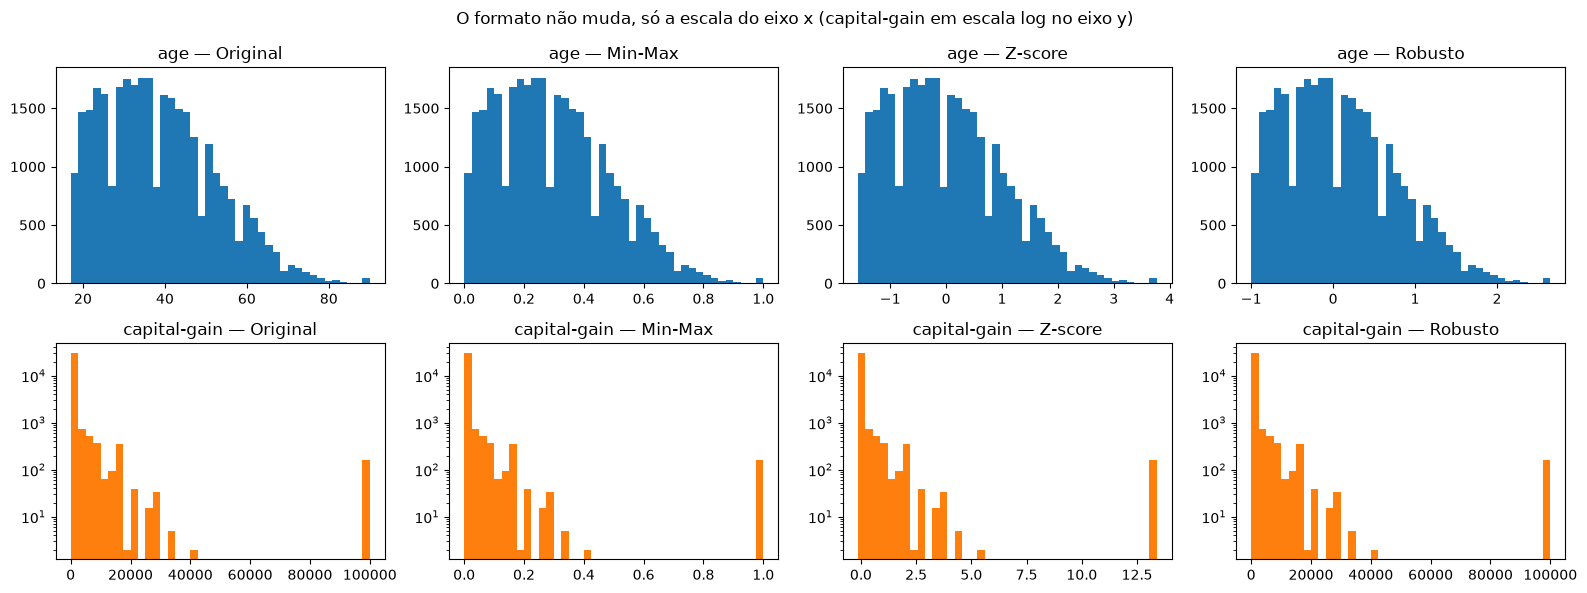

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
versoes = [('Original', df[num_cols]), ('Min-Max', df_minmax), ('Z-score', df_zscore), ('Robusto', df_robusto)]
for j, (nome, d) in enumerate(versoes):
    axes[0, j].hist(d['age'], bins=40, color='tab:blue')
    axes[0, j].set_title(f'age — {nome}')
    axes[1, j].hist(d['capital-gain'], bins=40, color='tab:orange')
    axes[1, j].set_title(f'capital-gain — {nome}')
    axes[1, j].set_yscale('log')
plt.suptitle('O formato não muda, só a escala do eixo x (capital-gain em escala log no eixo y)')
plt.tight_layout()
plt.show()

In [21]:
# onde fica a "maioria" das pessoas que tem algum ganho de capital, em cada escala?
tem_ganho = df['capital-gain'] > 0
print('Mediana de capital-gain entre quem tem ganho (>0):')
for nome, d in versoes:
    print(f'   {nome:9s}: {d.loc[tem_ganho.values, "capital-gain"].median():>10.4f}   (máximo: {d["capital-gain"].max():.4f})')

Mediana de capital-gain entre quem tem ganho (>0):
   Original :  7298.0000   (máximo: 99999.0000)
   Min-Max  :     0.0730   (máximo: 1.0000)
   Z-score  :     0.8423   (máximo: 13.3946)
   Robusto  :  7298.0000   (máximo: 99999.0000)


**O que eu vi na comparação:**

- **Min-Max** coloca tudo entre 0 e 1, como prometido. Em `age` e `hours-per-week` funciona bem. Mas em `capital-gain`, como existem 159 pessoas com o valor 99.999 (que parece um teto/código do censo), quase todo mundo fica espremido perto de 0: a mediana de quem tem algum ganho fica em ~0,07. A escala é "gasta" pelos extremos.
- **Z-score** deixa média 0 e desvio 1 em todas as colunas, mas a faixa varia muito. `age` vai de -1,6 a 3,8, enquanto `capital-gain` vai até **13,4** e `capital-loss` até 10,6. Ou seja, nas colunas com extremos ainda sobram valores muito "fora" depois de escalonar.
- **Robusto** usa mediana e IQR. Em `age`, `fnlwgt` e `education-num` ficou parecido com o Z-score. Em `hours-per-week` a faixa ficou bem maior (-7,8 a 11,8), porque quase todo mundo trabalha entre 40 e 45 horas e o IQR é só 5 horas: quem foge disso vira um valor "grande". Mas em `capital-gain` e `capital-loss` o IQR é **zero** (Q1 = Q3 = 0), então o scaler não tem como dividir por nada. O scikit-learn, nesse caso, usa escala 1, e os valores **saem exatamente iguais aos originais** (0 a 99.999). Ou seja, o escalonamento robusto simplesmente não faz nada nessas colunas.
- Nos histogramas dá para ver que nenhuma das três técnicas muda o **formato** da distribuição, só a escala do eixo x. Se a ideia for lidar com a assimetria, seria preciso uma transformação (log, por exemplo), não um scaler.

## Respostas às perguntas de reflexão

**1. Por que `df.isna().sum()` pode retornar zero em todas as colunas de um dataset que, na verdade, tem dados faltando?**

Porque o `isna()` só reconhece o que o pandas entende como ausente: `NaN`, `None`, `NaT` e, na leitura do CSV, alguns textos padrão (`''`, `'NA'`, `'NaN'`, `'null'`...). Se quem criou a base usou outro código para "não sei", como o `'?'` daqui, ou `'-'`, `'unknown'`, `0`, `-1`, `999`, para o pandas aquilo é um valor normal. No Adult isso ainda vem com um espaço na frente (`' ?'`), então mesmo que eu passasse `na_values='?'` sem tratar o espaço, ele não ia pegar. Por isso é importante olhar os valores únicos de cada coluna e ler a documentação, não confiar só no `isna()`.

**2. Na coluna `capital-gain`, a grande maioria dos valores é zero. Qual das três técnicas é mais afetada por isso?**

O **escalonamento robusto**. Com 91,7% de zeros, tanto o primeiro quanto o terceiro quartil são 0, e o IQR (que é o divisor do RobustScaler) fica 0. Nos meus resultados dá para ver: o `scale_` de `capital-gain` ficou 1 e a coluna depois do RobustScaler tem exatamente os mesmos valores da original (máximo 99.999). Na prática ela não foi escalonada, e continua numa escala milhares de vezes maior que as outras colunas, o que atrapalha qualquer modelo baseado em distância.

O Min-Max também sofre, mas por outro motivo: ele é afetado pelos extremos (99.999), não pelos zeros. E o Z-score fica no meio do caminho. Para essa coluna, eu provavelmente faria outra coisa: transformar com `log1p` ou criar uma variável binária "tem ganho de capital" (0/1) e escalonar só o valor de quem tem.

**3. Faz sentido escalonar todas as colunas numéricas? O que a coluna `fnlwgt` representa?**

Não necessariamente. Pesquisando na documentação (`adult.names`) e no site do UCI, o `fnlwgt` (*final weight*) é um **peso amostral** calculado pelo Census Bureau: ele diz quantas pessoas da população americana aquela linha "representa", com base em idade, sexo, raça e estado. Ele não é uma característica da pessoa, como idade ou escolaridade. Duas pessoas idênticas em tudo podem ter `fnlwgt` muito diferentes só porque moram em estados diferentes.

Então, para um modelo que tenta prever a renda de uma pessoa, faz mais sentido **não usar** o `fnlwgt` como variável de entrada (e, portanto, não precisa escalonar). O uso correto dele seria como peso da amostra (`sample_weight`) ou para calcular estatísticas que representem a população.

Outros casos parecidos: `education-num` é só o `education` convertido em número ordinal, então usar os dois é redundante. E modelos baseados em árvore (Decision Tree, Random Forest) nem precisam de escalonamento, porque dividem por limiares. Escalonar faz diferença em modelos de distância ou gradiente (KNN, SVM, regressão logística, redes neurais).